In [47]:
import gymnasium as gym

import numpy as np
import time
import matplotlib.pyplot as plt
import random 
import numpy as np
from collections import defaultdict
import copy 
 

env=gym.make('CartPole-v1')#,render_mode='human')

(state,_)=env.reset()

In [2]:
def treatState(state,pos_space,vel_space,ang_space,ang_vel_space):
    state[0]=np.digitize(state[0],pos_space)
    state[1]=np.digitize(state[1],vel_space)
    state[2]=np.digitize(state[2],ang_space)
    state[3]=np.digitize(state[3],ang_vel_space)
    return state

In [3]:
class IncrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [4]:
class DecrQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=(self.goal - abs(self.goal-result))/self.goal
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],(goal - abs(goal-result))/goal)"""

In [5]:
class STDQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.std=20
        self.goal=goal
        
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        if result < self.goal-self.std:
            reward=1
        elif result > self.goal+self.std:
            reward=-1
        else:
            reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            """if i < goal-10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],1)
                continue
            if i > goal+10:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],-1)
                continue"""
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [6]:
class Qlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.goal - abs(self.goal-result)
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma

In [7]:
class expQlearning():

    def __init__(self, epsilon, gamma, alpha, num_actions,goal,p=2):

   
        self.epsilon = epsilon
        self.gamma = gamma
        self.alpha = alpha
        self.Qvalues = defaultdict(lambda : np.repeat(0.0,num_actions))
        self.num_actions=num_actions
        self.goal=goal
        self.p=p
        

    def getQvalue(self, state, action):
        return self.Qvalues[state][action]

    
    """
    Compute the action to take in the current state.  With
    probability self.epsilon, we should take a random action and
    take the best policy action otherwise.  Note that if there are
    no legal actions, which is the case at the terminal state, you
    should choose None as the action.
    """
    def getAction(self, state):
        if random.random() < self.epsilon:
          return random.randint(0,self.num_actions-1)
        else:
          return np.argmax(self.Qvalues[state])
    
    """    
    update the qV of one state action with the knowledge of the reward
    """
    def update(self, state, action, nextState, reward):
      self.Qvalues[state][action] = self.getQvalue(state, action) + self.alpha * (reward + self.gamma * np.max(self.Qvalues[nextState])-  self.getQvalue(state, action))
        
    def _update_Q_table(self, Q, state, action, reward, next_state, Qp, num_agents):
        Q[state][action] = (1 - self.alpha) * Q[state][action] + self.alpha * (reward + self.gamma * 1/num_agents * np.max(Qp[next_state]))

    def increasing_reward(self,value):
        result=0
        k=0.01
        p=self.p
        if value < 0:
            return - abs((((1+k*value)**p)-1)/p)
        return (((1+k*value)**p)-1)/p
    
        if(value<0):
            for i in range(0,value,-1):
                result +=i
        else:
            for i in range(0,value):
                result +=i
        return result
    def episodeRewards(self,episodes):
        result=len(episodes)
        reward=self.increasing_reward(self.goal - abs(self.goal-result))
        
            
        for i in range(len(episodes)-1,-1,-1):
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],reward)
            reward*=self.gamma
        """for i in range(len(episodes)):
            if i==len(episodes)-1:
                self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result)))
                break
            self.update(episodes[i][0],episodes[i][1],episodes[i][2],self.increasing_reward(goal - abs(goal-result) ))"""

In [8]:
def uniTraining(goal,episodeNumber=30000,type="inc",p=2):
    timeSteps=10000
    episodesResults=[]
    episodesTestResults=[]
    episodesTestResultsDeviation=[]
    numberOfTest=50
    if type == "inc":
        qagent= IncrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "dec":
        qagent= DecrQlearning(0.1,0.99,0.1,2,goal)
    elif type == "std":
        qagent= STDQlearning(0.1,0.99,0.1,2,goal)
    elif type == "base":
        qagent= Qlearning(0.1,0.99,0.1,2,goal)
    elif type == "exp":
        qagent= expQlearning(0.1,0.99,0.1,2,goal,p)
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)

    for episodeIndex in range(episodeNumber):
       
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        #print("episode: ",episodeIndex)
        episodeObservation=[]
        for timeIndex in range(timeSteps):
            action=qagent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation.append([tuple(state),action,tuple(next_state)])
            #qagent.update(tuple(state),action,tuple(next_state),reward)
            state=next_state
            if (terminated):
                #print("Number of steps :",timeIndex)
                
                episodesResults.append(timeIndex)
                break
    
        qagent.episodeRewards(episodeObservation)
        if(episodeIndex %500 ==0):
            qagent.epsilon=0
            testResultList=[]
            for episodeIndex in range(numberOfTest):
        
                state,_=env.reset()
                state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
                for timeIndex in range(timeSteps):
                    action=qagent.getAction(tuple(state))
                    next_state, reward, terminated, truncated, info =env.step(action)
                    next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                    state=next_state
                    if (terminated):
                        testResultList.append(timeIndex)
                        break
    
            episodesTestResults.append(sum(testResultList)/len(testResultList))
            episodesTestResultsDeviation.append(np.std(episodesTestResults))
            qagent.epsilon=0.1
        
    
    
    env.close() 
    return episodesResults,episodesTestResults,episodesTestResultsDeviation,qagent

In [9]:
def uniTest(agent,epsilon=0):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    agent.epsilon=epsilon
    last1000testList=[]
    for episodeIndex in range(1000):
    
        state,_=env.reset()
        state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
        for timeIndex in range(timeSteps):
            action=agent.getAction(tuple(state))
            next_state, reward, terminated, truncated, info =env.step(action)
            next_state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
            state=next_state
            if (terminated):
                last1000testList.append(timeIndex)
                break
    return np.mean(last1000testList),np.std(last1000testList)

In [48]:
def failSafeTrain(qagent,goal):
    pos_space=np.linspace(-2.4,2.4,10)
    vel_space=np.linspace(4,4,10)
    ang_space=np.linspace(-0.2095,0.2095,10)
    ang_vel_space=np.linspace(-4,4,10)
    timeSteps=10000
    currentmean=uniTest(qagent)[0]
    Failsafe=30
    savedgoal=goal
    currentmin=abs(currentmean -savedgoal)
    currentAgent=copy.deepcopy(qagent)
    while abs(currentmean -savedgoal) > 0.05 * goal and Failsafe>0:
        goal-=int((currentmean -savedgoal)/10)
        qagent.epsilon=0.1
        for episodeIndex in range(1000):
       
            state,_=env.reset()
            state=state=treatState(state,pos_space,vel_space,ang_space,ang_vel_space)
            episodeObservation=[]
            for timeIndex in range(timeSteps):
                action=qagent.getAction(tuple(state))
                next_state, reward, terminated, truncated, info =env.step(action)
                next_state=state=treatState(next_state,pos_space,vel_space,ang_space,ang_vel_space)
                episodeObservation.append([tuple(state),action,tuple(next_state)])
                state=next_state
                if (terminated):
                    
                    break
        
            qagent.episodeRewards(episodeObservation)
        currentmean=uniTest(qagent)[0]
        Failsafe-=1
        if abs(currentmean -savedgoal) < currentmin:
            currentmin=abs(currentmean -savedgoal)
            currentAgent=copy.deepcopy(qagent)
    qagent=currentAgent
    goal=savedgoal
    return qagent

In [49]:
distancetomeanAll=[]
for goal in range(60,170,10):
    distancetomean=[]
    for type in range(0,11):
        _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
        agent=failSafeTrain(agent,goal)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/10)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll.append(distancetomean)

60 68.7127 32.18041001433544
60 60.372400000000006 20.200593232919037


KeyboardInterrupt: 

In [ ]:
avgstart=[]
for i in distancetomeanAll:
    plt.plot([x/10 for x in range(0,5)],i[:5])
    print(i[0:2])
    avgstart.append(i[0])
plt.legend([x for x in range(60,170,10)])
print(np.mean(avgstart))

In [ ]:
for i in [0,4,6]:
    plt.plot(distancetomeanAll[i])
plt.legend([0,4,6])

In [50]:
distancetomeanAll2=[]
for type in ["inc"]:
    distancetomean=[]
    for goal in range(60,170,10):
        _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
        agent=failSafeTrain(agent,goal)
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,0)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(abs(goal-np.mean(mean))/goal)
    distancetomeanAll2.append(distancetomean)

60 60.755500000000005 4.580085215754461
70 60.0062 6.533451621721781
80 76.58040000000001 14.240650122676502
90 115.1632 5.922663957022232
100 106.4731 5.411191332701641
110 124.0385 4.010070231471966
120 123.45239999999998 19.45738400388631
130 141.9848 4.6067034783240315
140 136.5345 5.264483144681225
150 147.3839 6.081396875939973
160 152.08589999999998 6.234186566245635


[0.01259166666666675, 0.14276857142857144]
0.01259166666666675


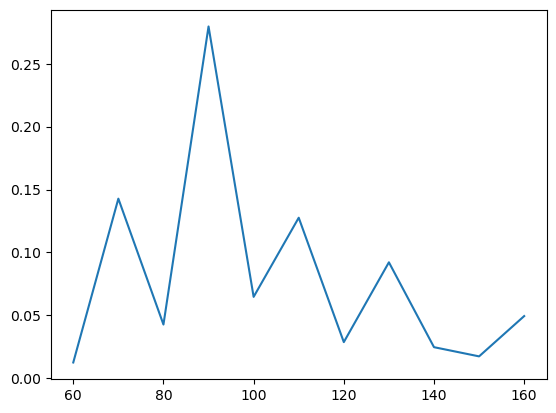

In [51]:
avgstart=[]
for i in distancetomeanAll2:
    plt.plot([x for x in range(60,170,10)],i)
    print(i[0:2])
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.savefig("SVG/MultiGoalIncreasedmean.svg")

In [22]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(90,150,10):
    distancetomean=[]
    distancetostd=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std))
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

90 114.89439999999999 9.889214774761733
90 113.7982 11.857984327022285
90 112.31300000000002 14.066622788253207
90 111.4573 15.446991032826253
90 110.02799999999999 17.04238269636747
90 108.80730000000001 18.12296497051574
90 107.82839999999999 19.066314629082843
90 106.05239999999999 20.603312051182492
90 104.8653 21.740695513634048
90 103.0479 22.910222257458106
90 101.7104 24.181640330775604
90 100.5189 24.74654668196013
90 98.9775 25.47370896380408
90 97.3775 26.075339469440046
90 96.48670000000001 26.408453941978223
90 94.63840000000002 27.402054678973364
90 93.11229999999999 27.952574393477278
90 92.13380000000001 28.324201161137562
90 89.5249 29.71112818615422
90 88.2034 29.86352102093794
90 86.79100000000001 30.256976259205327
90 86.05609999999999 30.504851704108166
90 84.2885 30.932440590801775
90 82.695 31.335782728440893
90 81.44460000000001 32.07498848694678
90 80.203 31.916684631642987
90 78.71579999999999 32.090400472735325
90 76.764 32.58641974793785
90 75.25899999999999

121.12931666666668


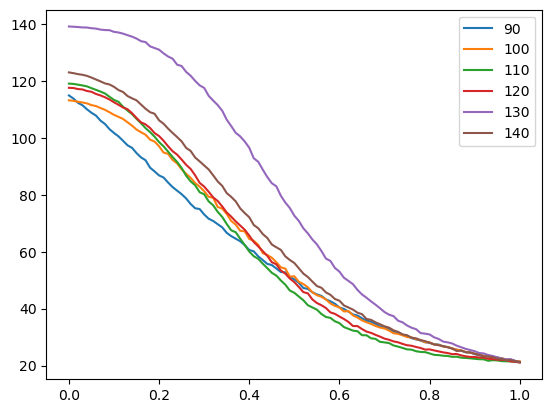

In [28]:
avgstart=[]
for i in distancetomeanAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(90,150,10)])
plt.savefig("SVG/MultiGoalIncreasedRand1.svg")

In [ ]:
avgstart=[]
for i in distancetoSTDAll3:
    plt.plot([x/100 for x in range(0,101)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(90,150,10)])
plt.savefig("SVG/MultiGoalIncreasedRan2.svg")

y = 77.12x² + -174.08x + 117.97
y = 74.28x² + -179.97x + 124.63
y = 111.41x² + -225.16x + 133.10
y = 91.42x² + -204.90x + 131.42
y = 32.28x² + -179.16x + 156.93
y = 74.73x² + -193.67x + 136.07


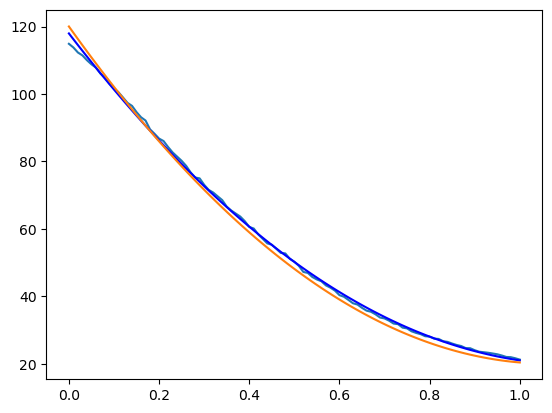

In [34]:
x_points = np.linspace(0,1,101)
coeffsall=[]
polyall=[]
for i in range(len(distancetomeanAll3)):
    coeffsall.append(np.polyfit(x_points, distancetomeanAll3[i], deg=2))
    polyall.append(np.poly1d(coeffsall[i]))
    
 
x_fit = np.linspace(min(x_points), max(x_points), 100)
y_fitall=[]
for i in polyall:
    y_fitall.append(i(x_fit))

equationall=[]
for i in coeffsall:
    equationall.append(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")
    print(f"y = {i[0]:.2f}x² + {i[1]:.2f}x + {i[2]:.2f}")



for i in distancetomeanAll3[0:1]:
    plt.plot([x/100 for x in range(0,101)],i)
plt.plot(x_fit, y_fitall[0], color='blue')
coefftest=[-0.45*90+128.77,-0.22*90-168.10, 0.53*90+72.33]
polytest = np.poly1d(coefftest)  
y_fittest = polytest(x_fit)
plt.plot(x_fit,y_fittest)

In [ ]:
v= 130
coefftest=[90 - (v-90)/5,-190, v+30]
polytest = np.poly1d(coefftest)  
y_fittest = polytest(x_fit)
plt.plot(x_fit, y_fittest, color='red', label=equation)
plt.plot(x_fit, y_fit3, color='blue', label=equation)
plt.plot([x/100 for x in range(0,101)],distancetomeanAll3[4])

In [25]:
x_points = np.linspace(0,1,101)
x_fit = np.linspace(min(x_points), max(x_points), 100)
distancetoestall=[]
for goal in range(90,150,10):
    coefftest=[-0.45*goal+128.77,-0.22*goal-168.10, 0.53*goal+72.33]
    polytest = np.poly1d(coefftest)  
    y_fittest = polytest(x_fit)
   
    distancetoest=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,100):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1])
        print(goal,np.mean(mean),np.mean(std),abs(np.mean(mean) - y_fittest[type]) )
        distancetoest.append(abs(np.mean(mean) - y_fittest[type]) )
        
    distancetoestall.append(distancetoest)
    

90 102.1852 47.108245809175266 17.844800000000006
90 101.9999 47.522400407412434 16.141126425874916
90 102.0736 47.16230441817156 14.196465299459234
90 100.77420000000001 47.754984322479416 13.642916620752985
90 100.9623 47.541283210991146 11.619880389756148
90 99.93939999999999 47.24797547362573 10.825856606468733
90 99.05339999999998 47.21490520039971 9.912945270890745
90 97.5175 47.78037746642702 9.66794638302214
90 96.5412 47.151901572948944 8.881359942862971
90 95.10650000000001 47.49323584746776 8.57118595041321
90 94.297 46.75770783647862 7.653824405672893
90 92.6421 47.631445936793064 7.59987530864197
90 91.2861 47.318596290231234 7.265038659320467
90 90.2827 46.703547545734395 6.595614457708393
90 88.51129999999999 47.33095560462669 6.712202703805744
90 87.2654 46.89387650688057 6.321303397612496
90 84.9314 46.672290403399664 7.036516539128655
90 84.0633 46.71965091732909 6.303842128354248
90 81.68199999999999 46.30640614065272 7.102380165289276
90 80.7377 46.46896093765706 6.

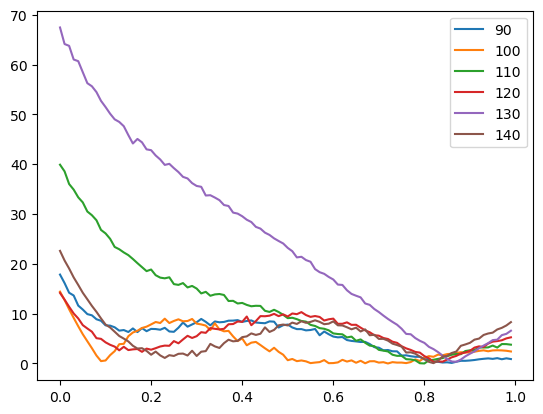

In [27]:
for i in distancetoestall:
    plt.plot([x/100 for x in range(0,100)],i)
plt.legend([x for x in range(90,150,10)])
plt.savefig("SVG/Estimation1.svg")

In [ ]:
distancetomeanAll3=[]
distancetoSTDAll3=[]
for goal in range(120,200,10):
    distancetomean=[]
    distancetostd=[]
    _,_,_,agent=uniTraining(goal,episodeNumber=30000,type="inc",p=3.5)
    for type in range(0,101):
        mean=[]
        std=[]
        for i in range(10):
            testresult=uniTest(agent,epsilon=type/100)
            mean.append(testresult[0])
            std.append(testresult[1]) 
        print(goal,np.mean(mean),np.mean(std))
        if np.mean(mean) < 130 - 13 and len(distancetomean)>0 and distancetomean[-1]<130-13:
            break
        distancetomean.append(np.mean(mean))
        distancetostd.append(np.mean(std))
    distancetomeanAll3.append(distancetomean)
    distancetoSTDAll3.append(distancetostd)

In [ ]:
avgstart=[]
for i in distancetomeanAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan3.svg")

In [ ]:
avgstart=[]
for i in distancetomeanAll3[1:-1]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])
plt.savefig("SVG/MultiGoalIncreasedRan4.svg")

In [ ]:
avgstart=[]
for i in distancetoSTDAll3[1:-4]:
    plt.plot([x/100 for x in range(0,101)][:len(i)],i)
    avgstart.append(i[0])

print(np.mean(avgstart))
plt.legend([x for x in range(130,200,10)])